# PCA and Kalman statistical arbitrage

Compare five strategy variants across four 15-stock universes on the retained 2017–2021 historical sample. Every figure starts after all portfolios are active and uses common calendar bounds across the four universes. Initial no-position history is excluded from the reported performance.

This period was retained after comparing date ranges. Results are historical and should not be presented as independent validation or evidence of stability across regimes.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from equity_stat_arb.period_comparison import run
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/equity_stat_arb").exists())
manifest = run(ROOT)
OUTPUT = ROOT / "artifacts/period_comparison"
metrics = pd.read_csv(OUTPUT / "metrics.csv")
daily = pd.read_parquet(OUTPUT / "daily_returns.parquet")
display(pd.DataFrame(manifest["samples"]))

Evaluating 2017-2021: technology


Evaluating 2017-2021: financial


Evaluating 2017-2021: energy


Evaluating 2017-2021: uk_external


   sample    universe                         variant  sharpe   cagr  max_drawdown
2017-2021  technology            Fixed Kalman / equal  0.5584 0.0561       -0.1413
2017-2021  technology Calibrated Kalman / inverse vol  0.2230 0.0189       -0.2153
2017-2021   financial            Fixed Kalman / equal  0.7104 0.0599       -0.1106
2017-2021   financial Calibrated Kalman / inverse vol  0.5198 0.0453       -0.1418
2017-2021      energy            Fixed Kalman / equal  0.2622 0.0274       -0.1623
2017-2021      energy Calibrated Kalman / inverse vol  0.4161 0.0482       -0.1243
2017-2021 uk_external            Fixed Kalman / equal  0.7982 0.0736       -0.1402
2017-2021 uk_external Calibrated Kalman / inverse vol  0.7024 0.0601       -0.1300


,sample,start,end,zero_exposure_rows
0,2017-2021,2018-07-09,2021-12-31,0


## Data and periods

Adjusted daily closes are downloaded directly from Yahoo Finance through `yfinance` and retained as checksummed local snapshots. All 60 configured stock histories are used; no name is replaced based on returns.

The model and signal-history windows use the configured 2017–2021 observations. After warmup, the reporting window starts on the first shared date when every universe has positions. US and UK trading-day counts can still differ because of holidays. The local price cache can contain a wider history; observations outside the configured input dates are excluded.

The active window is 9 July 2018–31 December 2021. All series have exactly the same first and last calendar date. There are no initial zero-exposure rows in the figures, and all five variants are plotted.

,universe,first_date,last_date,observations,sha256
0,technology,2017-01-03,2026-08-07,2412,2da61be71549ee05852d0312a880b446a93926df757e6e...
1,financial,2017-01-03,2026-08-07,2412,a98b31d7f7ebbac8796e6efa084ceeed76132b18c2a2c0...
2,energy,2017-01-03,2026-08-07,2412,18b4d1e01ae1fe421f124cee25398a794db2766669848e...
3,uk_external,2017-01-03,2026-08-07,2420,0309df2e0c2d23208553ce5563f6936e49285d98131656...


2017-2021 — active period: 2018-07-09 to 2021-12-31


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
universe,,,,,
energy,0.440,0.416,0.262,0.234,0.262
financial,0.547,0.520,0.710,0.700,0.527
technology,0.410,0.223,0.558,0.337,0.548
uk_external,0.740,0.702,0.798,0.753,0.798


,universe,variant,days,cagr,max_drawdown,average_daily_turnover
2,technology,PCA / equal,879,0.0547,-0.1472,0.0834
6,technology,Fixed Kalman / equal,879,0.0561,-0.1413,0.0834
10,technology,Calibrated Kalman / equal,879,0.0400,-0.1815,0.0842
14,technology,Fixed Kalman / inverse vol,879,0.0316,-0.1793,0.0859
18,technology,Calibrated Kalman / inverse vol,879,0.0189,-0.2153,0.0862
22,financial,PCA / equal,879,0.0418,-0.1123,0.0842
26,financial,Fixed Kalman / equal,879,0.0599,-0.1106,0.0842
30,financial,Calibrated Kalman / equal,879,0.0478,-0.1253,0.0842
34,financial,Fixed Kalman / inverse vol,879,0.0596,-0.1281,0.0851
38,financial,Calibrated Kalman / inverse vol,879,0.0453,-0.1418,0.0851


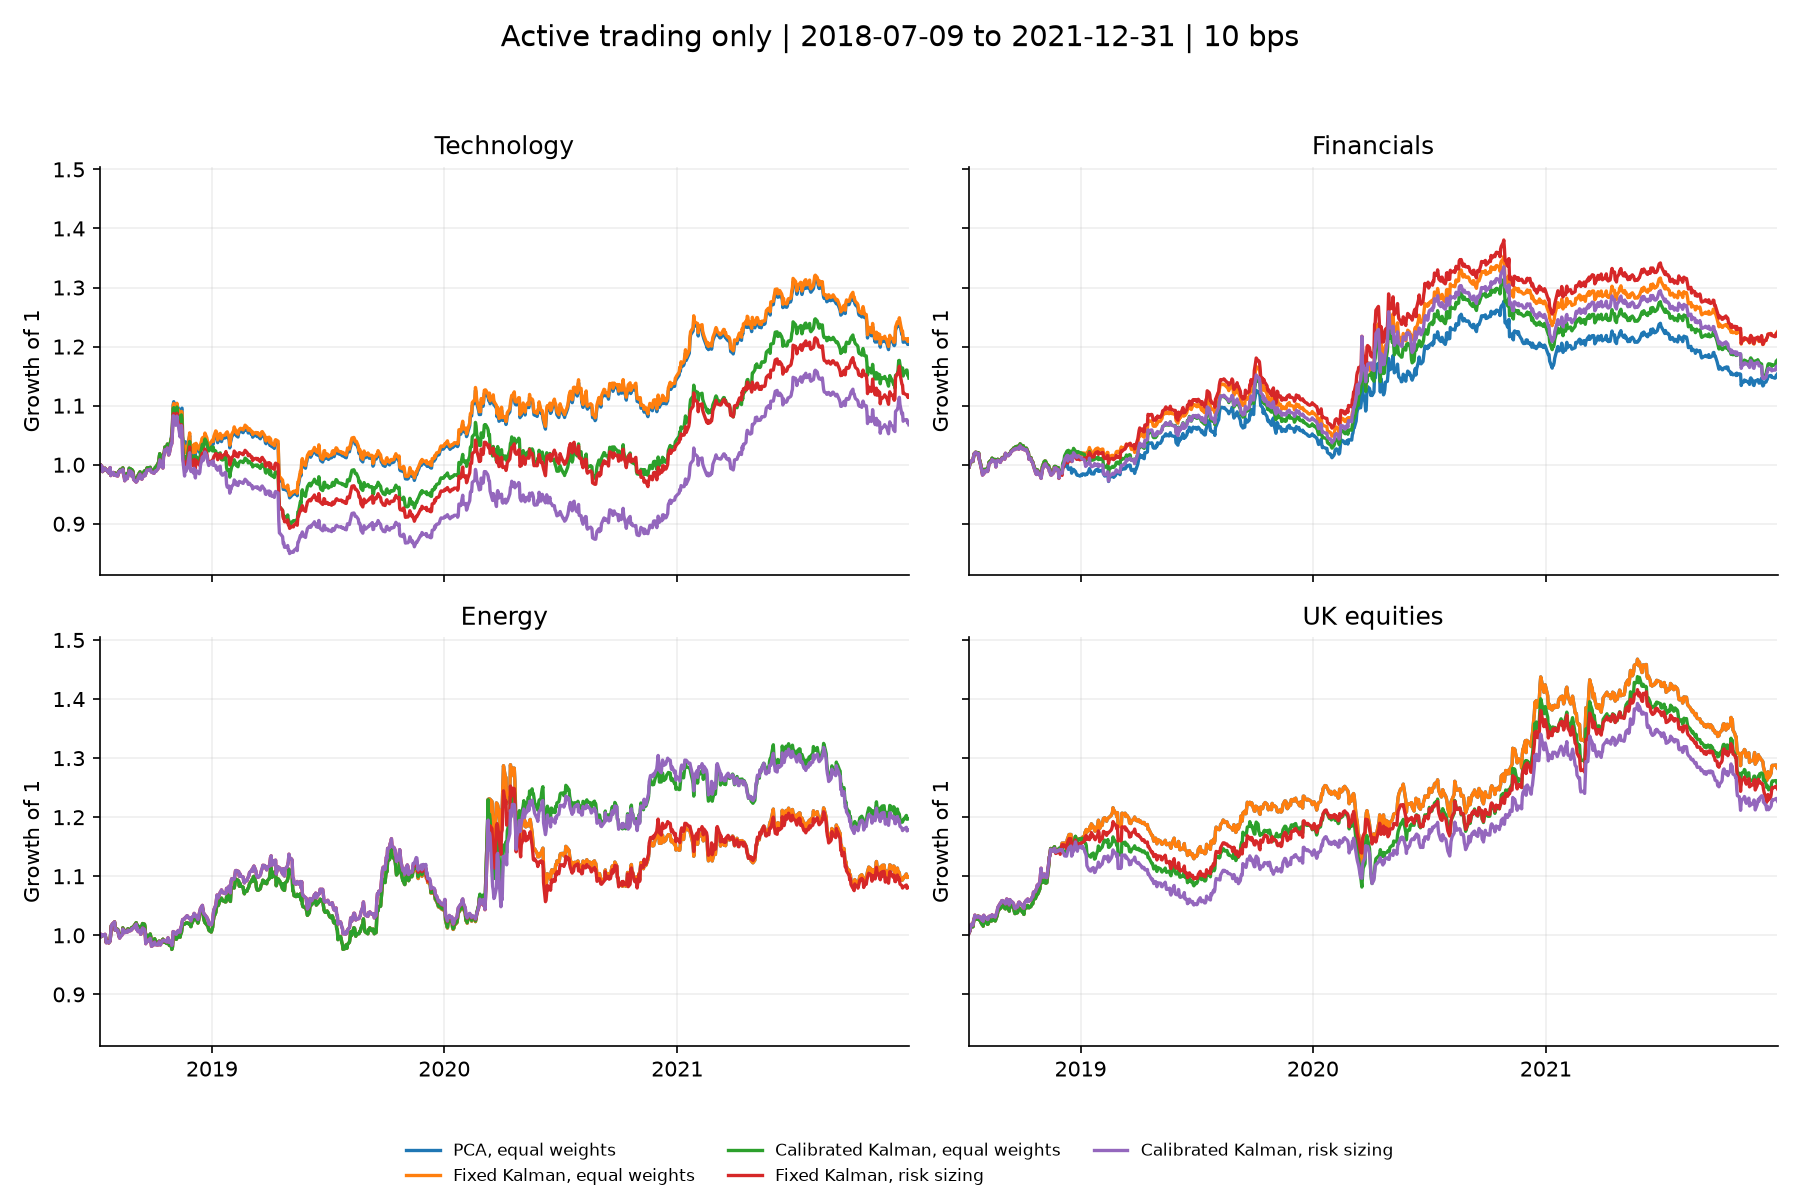

In [2]:
display(pd.DataFrame(manifest["prices"])[["universe", "first_date", "last_date", "observations", "sha256"]])
at_10 = metrics[metrics.cost_bps == 10]
for sample in manifest["samples"]:
    name = sample["sample"]
    print(name, "— active period:", sample["start"], "to", sample["end"])
    subset = at_10[at_10["sample"] == name]
    display(subset.pivot(index="universe", columns="variant", values="sharpe").round(3))
    display(subset[["universe", "variant", "days", "cagr", "max_drawdown", "average_daily_turnover"]].round(4))
    display(Image(filename=str(OUTPUT / (name + ".png"))))

## Models and signals

Correlation PCA uses 126 past trading days, refits every 10 days and retains the factor count required for 55% explained variance.

$$r^{std}_{i,t}=\alpha_{i,t}+\beta_{i,t}^{\top}f_t+\epsilon_{i,t}.$$

Kalman residuals are innovations recorded before updating the state. The filter resets for each PCA basis. The fixed variant uses Q=1e-4. Calibration scores Q=0, 1e-4 or 1e-2 using sequential Gaussian likelihood: the first 84 past observations fit PCA/scaling/noise and the last 42 score the candidates. Production then fits all 126 past observations. No trading profit enters this choice.

The signal ranks negative five-day residual pressure divided by 20-day residual volatility. Three longs and three shorts are selected every 20 days after 252 residual observations of initial history. Inverse-volatility sizing uses raw returns from the preceding 20 days, with 50% per side and a 25% target weight cap.

Targets are lagged one day. Daily weights are treated as constant until the next signal rebalance; costs cover changes in those targets only. Holding drift and weight-maintenance trades are omitted. This remains a simplified research accounting model.

## Cost sensitivity

The five variants use the same evaluation dates and turnover-cost convention. All five curves appear in the figure: PCA, fixed Kalman, calibrated Kalman, fixed Kalman with risk sizing, and calibrated Kalman with risk sizing.

In [3]:
for sample in metrics["sample"].unique():
    for universe in metrics.universe.unique():
        print(sample, universe)
        subset = metrics[(metrics["sample"] == sample) & (metrics.universe == universe)]
        display(subset.pivot(index="cost_bps", columns="variant", values="sharpe").round(3))
selected = at_10
print("Descriptive average/median across universes, NOT a portfolio Sharpe:")
display(selected.groupby(["sample", "variant"]).sharpe.agg(["mean", "median"]).round(3))

2017-2021 technology


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,0.603,0.417,0.755,0.535,0.745
5,0.506,0.320,0.657,0.436,0.646
10,0.410,0.223,0.558,0.337,0.548
20,0.217,0.030,0.362,0.140,0.351


2017-2021 financial


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,0.774,0.749,0.952,0.941,0.777
5,0.661,0.635,0.832,0.821,0.652
10,0.547,0.520,0.710,0.700,0.527
20,0.319,0.290,0.466,0.456,0.275


2017-2021 energy


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,0.589,0.572,0.410,0.392,0.410
5,0.514,0.494,0.336,0.313,0.336
10,0.440,0.416,0.262,0.234,0.262
20,0.291,0.260,0.114,0.076,0.114


2017-2021 uk_external


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,0.959,0.941,1.015,0.991,1.015
5,0.850,0.822,0.907,0.873,0.907
10,0.740,0.702,0.798,0.753,0.798
20,0.521,0.463,0.580,0.515,0.580


Descriptive average/median across universes, NOT a portfolio Sharpe:


mean  median
sample    variant                                       
2017-2021 Calibrated Kalman / equal        0.534   0.494
          Calibrated Kalman / inverse vol  0.465   0.468
          Fixed Kalman / equal             0.582   0.634
          Fixed Kalman / inverse vol       0.506   0.518
          PCA / equal                      0.534   0.537

## Notes

Adding calibration and risk sizing helps energy, but does not consistently improve the reference in the other universes. The historical period was retained after comparison and does not establish a stable edge across regimes.

Charts use the same axes within each sample, begin with active trading and contain no artificial initial flat year. Metrics are recalculated over those exact calendar bounds; they are not copied from the earlier mixed-period experiment.

Limitations include inspected histories, hand-picked universes, possible survivorship bias, constant-target-weight accounting and omitted borrow/financing/impact costs. Dollar neutrality is not factor neutrality. There is no Robust PCA or C++ implementation.

The separate archived numerical reproduction remains available through `python -m equity_stat_arb.pipeline --verify`. Its mixed-period inputs and initial flat-day convention are not the headline analysis here. Source details are preserved in its manifest.

Run `python -m equity_stat_arb.period_comparison` to regenerate this comparison and `python -m pytest -q` for the numerical checks.